# Prédiction de la résistance aux antibiotiques — pipeline par antibiotique

Le pipeline complet est implémenté dans `src/pipeline.py` et importé ici. Il permet de traiter 1, 8 ou 48 antibiotiques sans copier-coller.

## 1. Imports et configuration

In [1]:
from pathlib import Path
import sys
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

## 2. Chargement des splits

Le chemin est résolu de façon à fonctionner que le notebook soit lancé depuis `notebooks/` ou depuis la racine du dépôt.

In [2]:
def find_splits_dir() -> Path:
    candidates = [
        Path("../data/splits_all_snp_3way"),
        Path("data/splits_all_snp_3way"),
    ]
    for candidate in candidates:
        if (candidate / "X_train.parquet").exists():
            return candidate.resolve()
    raise FileNotFoundError(
        "Impossible de trouver data/splits_all_snp_3way. "
        "Lance le notebook depuis la racine du dépôt ou depuis notebooks/."
    )

DATA = find_splits_dir()
REPO_ROOT = DATA.parent.parent
sys.path.insert(0, str(REPO_ROOT))

MODEL_DIR = REPO_ROOT / "models" / "by_atb"
REPORT_DIR = REPO_ROOT / "reports"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("DATA       :", DATA)
print("REPO_ROOT  :", REPO_ROOT)
print("MODEL_DIR  :", MODEL_DIR)
print("REPORT_DIR :", REPORT_DIR)

DATA       : /Users/hin.benjamin/Projet_ML_DL/Projet_ML_DL/data/splits_all_snp_3way
REPO_ROOT  : /Users/hin.benjamin/Projet_ML_DL/Projet_ML_DL
MODEL_DIR  : /Users/hin.benjamin/Projet_ML_DL/Projet_ML_DL/models/by_atb
REPORT_DIR : /Users/hin.benjamin/Projet_ML_DL/Projet_ML_DL/reports


In [3]:
SPLITS = ("train", "val", "test")
data = {}

for split in SPLITS:
    data[f"X_{split}"] = pd.read_parquet(DATA / f"X_{split}.parquet")
    data[f"Y_{split}"] = pd.read_parquet(DATA / f"Y_{split}.parquet")
    if not data[f"X_{split}"].index.equals(data[f"Y_{split}"].index):
        raise ValueError(f"Index désalignés pour le split {split}")

n_features = data["X_train"].shape[1]
n_drugs = data["Y_train"].shape[1]
n_total = sum(len(data[f"X_{split}"]) for split in SPLITS)

print(f"{n_total:,} génomes au total | {n_features:,} features | {n_drugs} antibiotiques")
for split in SPLITS:
    print(
        f"{split:5s} : X={data[f'X_{split}'].shape} "
        f"| Y={data[f'Y_{split}'].shape} "
        f"| dtype X={data[f'X_{split}'].dtypes.iloc[0]}"
    )

6,949 génomes au total | 34,744 features | 48 antibiotiques
train : X=(4722, 34744) | Y=(4722, 48) | dtype X=uint8
val   : X=(1110, 34744) | Y=(1110, 48) | dtype X=uint8
test  : X=(1117, 34744) | Y=(1117, 48) | dtype X=uint8


## 3. Couverture du phénotype par antibiotique

Avant d'entraîner quoi que ce soit, on vérifie combien d'individus sont testés et quelle est la prévalence de la résistance sur chaque split.

In [4]:
def coverage_table(data: dict) -> pd.DataFrame:
    rows = []
    for atb in data["Y_train"].columns:
        row = {"atb": atb}
        for split in SPLITS:
            y = data[f"Y_{split}"][atb]
            n = int(y.notna().sum())
            n_r = int((y == 1).sum())
            row[f"n_{split}"] = n
            row[f"pct_R_{split}"] = round(100 * n_r / n, 1) if n else np.nan
        rows.append(row)
    return pd.DataFrame(rows).set_index("atb")


coverage = coverage_table(data)
coverage["n_min"] = coverage[[f"n_{split}" for split in SPLITS]].min(axis=1)
coverage = coverage.sort_values("n_test", ascending=False)
coverage.to_csv(REPORT_DIR / "coverage_by_atb.csv")
coverage

,n_train,pct_R_train,n_val,pct_R_val,n_test,pct_R_test,n_min
atb,,,,,,,
ciprofloxacin,4050,23.5,946,17.9,939,17.6,939
gentamicin,4042,10.3,935,9.4,933,9.1,933
ceftazidime,3881,10.2,943,7.5,921,9.6,921
piperacillin/tazobactam,3823,4.3,902,5.7,892,3.6,892
cefotaxime,3654,16.7,862,8.9,852,11.5,852
ampicillin,3245,51.1,822,48.2,784,47.8,784
meropenem,3233,0.4,680,0.7,721,0.6,680
cefuroxime,2676,14.3,769,11.6,656,11.0,656
amoxicillin/clavulanic acid,2542,29.7,560,31.1,608,31.1,560


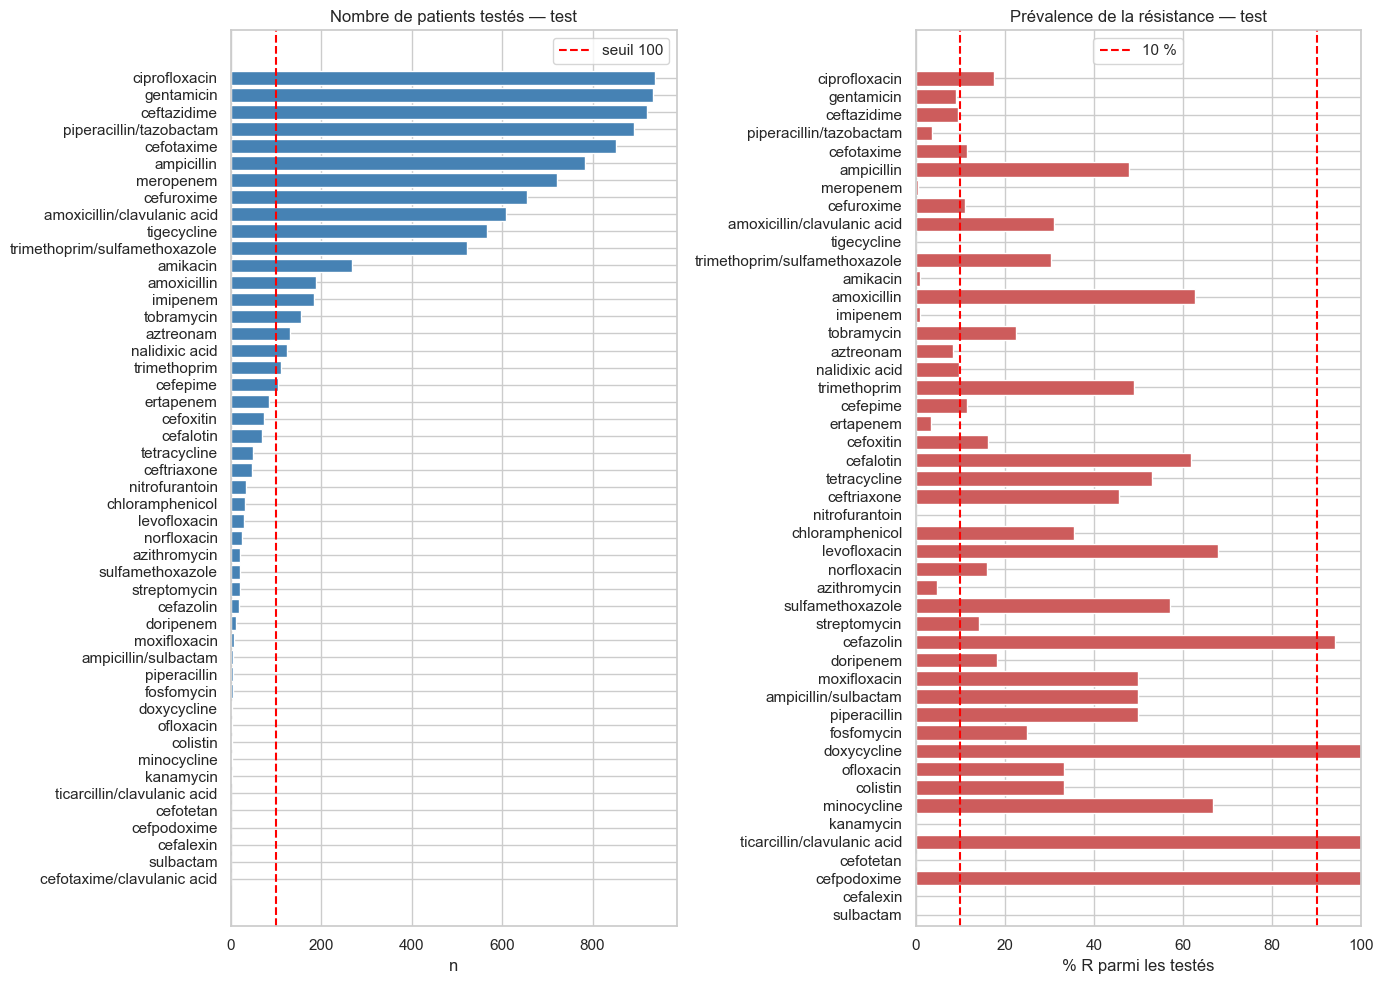

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 10))

order = coverage.sort_values("n_test")

axes[0].barh(order.index, order["n_test"], color="steelblue")
axes[0].axvline(100, color="red", linestyle="--", label="seuil 100")
axes[0].set_title("Nombre de patients testés — test")
axes[0].set_xlabel("n")
axes[0].legend()

axes[1].barh(order.index, order["pct_R_test"], color="indianred")
axes[1].axvline(10, color="red", linestyle="--", label="10 %")
axes[1].axvline(90, color="red", linestyle="--")
axes[1].set_xlim(0, 100)
axes[1].set_title("Prévalence de la résistance — test")
axes[1].set_xlabel("% R parmi les testés")
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Quels antibiotiques sont exploitables ?

Deux critères sont calculés :

- **strict** : au moins 100 individus testés et au moins 10 % de classe minoritaire sur chacun des trois splits ;
- **élargi** : au moins 100 individus testés et au moins 5 % de classe minoritaire.

Le seuil de 100 est un paramètre du pipeline (`min_samples`) ; on peut le monter à 300 pour ne garder que les antibiotiques les plus solides.

In [6]:
MIN_SAMPLES = 100


def is_eligible(row, min_minority_pct: float) -> bool:
    for split in SPLITS:
        n = row[f"n_{split}"]
        pct = row[f"pct_R_{split}"]
        if n < MIN_SAMPLES or not (0 < pct < 100):
            return False
        if min(pct, 100 - pct) < min_minority_pct:
            return False
    return True


coverage["eligible_10"] = coverage.apply(
    is_eligible, axis=1, min_minority_pct=10.0
)
coverage["eligible_5"] = coverage.apply(
    is_eligible, axis=1, min_minority_pct=5.0
)

for label, column in [
    ("strict (>= 10 % minoritaire)", "eligible_10"),
    ("élargi (>= 5 % minoritaire)", "eligible_5"),
]:
    atbs = coverage.index[coverage[column]].tolist()
    print(f"{label} : {len(atbs)} antibiotiques")
    print("  ", atbs)
    print()

strict (>= 10 % minoritaire) : 9 antibiotiques
   ['ciprofloxacin', 'ampicillin', 'cefuroxime', 'amoxicillin/clavulanic acid', 'trimethoprim/sulfamethoxazole', 'amoxicillin', 'tobramycin', 'trimethoprim', 'cefepime']

élargi (>= 5 % minoritaire) : 14 antibiotiques
   ['ciprofloxacin', 'gentamicin', 'ceftazidime', 'cefotaxime', 'ampicillin', 'cefuroxime', 'amoxicillin/clavulanic acid', 'trimethoprim/sulfamethoxazole', 'amoxicillin', 'tobramycin', 'aztreonam', 'nalidixic acid', 'trimethoprim', 'cefepime']



## 5. Antibiotiques ciblés

On garde les **5 antibiotiques qui respectent le critère strict**.

On ajoute 3 antibiotiques supplémentaires, utiles mais avec une classe minoritaire entre 7 % et 10 % sur la validation ou le test :

- `gentamicin` ;
- `ceftazidime` ;
- `cefotaxime`.

Pour lancer **tous** les antibiotiques qui passent le critère élargi, décommenter la dernière ligne.

In [7]:
ATB_CIBLES = [
    # 5 ATB avec au moins 10 % de classe minoritaire sur train/val/test
    "ciprofloxacin",
    "ampicillin",
    "cefuroxime",
    "amoxicillin/clavulanic acid",
    "trimethoprim/sulfamethoxazole",
    # 3 ATB supplémentaires, classe minoritaire entre 7 % et 10 %
    "gentamicin",
    "ceftazidime",
    "cefotaxime",
]

# Pour traiter tous les ATB éligibles au critère élargi :
# ATB_CIBLES = coverage.index[coverage["eligible_5"]].tolist()

missing = [atb for atb in ATB_CIBLES if atb not in data["Y_train"].columns]
assert not missing, f"ATB absents des colonnes de Y : {missing}"
ATB_CIBLES

['ciprofloxacin',
 'ampicillin',
 'cefuroxime',
 'amoxicillin/clavulanic acid',
 'trimethoprim/sulfamethoxazole',
 'gentamicin',
 'ceftazidime',
 'cefotaxime']

## 6. Fonctions du pipeline

Les fonctions sont dans `src/pipeline.py` pour rester réutilisables hors du notebook :

- `prepare_data_for_atb` : filtre les lignes testées pour un ATB sur les trois splits ;
- `run_antibiotic_pipeline` : entraîne XGBoost et une régression logistique L1, choisit le modèle et le seuil sur la validation, évalue sur le test, calcule SHAP et sauvegarde le modèle.

Le seuil est choisi sur la **validation** (F1), jamais sur le test.

In [8]:
from src.pipeline import (
    AntibioticResult,
    prepare_data_for_atb,
    run_antibiotic_pipeline,
)

## 7. Exemple complet : ciprofloxacine

On lance d'abord le pipeline sur un seul antibiotique, avec SHAP activé, pour vérifier que tout fonctionne et inspecter les variables importantes.

In [9]:
res_cipro = run_antibiotic_pipeline(
    atb="ciprofloxacin",
    data=data,
    compute_shap=True,
    shap_background=1000,
    save_dir=MODEL_DIR,
    verbose=True,
)


=== ciprofloxacin ===
n_train=4050 | n_val=946 | n_test=939
prévalence train/val/test = 23.48% / 17.86% / 17.57%
  xgb    | val PR-AUC=0.968 | val F1=0.958 @ seuil=0.048
  lr_l1  | val PR-AUC=0.961 | val F1=0.955 @ seuil=0.680
  → meilleur modèle : xgb (seuil validation = 0.048)
  TEST   | AUC=0.982 | PR-AUC=0.977 | F1=0.946 | P=0.940 | R=0.952


In [10]:
pd.DataFrame(res_cipro.metrics_test).T.round(4)

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc,threshold
xgb,0.9808,0.9693,0.9401,0.9515,0.9458,0.9820,0.9769,0.048
lr_l1,0.9819,0.9533,0.9868,0.9091,0.9464,0.9811,0.9680,0.680


In [11]:
res_cipro.feature_importance.head(20)

,feature,mean_abs_shap
0,parC_Ser80Ile,3.588600
1,gyrA_Ser83Leu,1.356949
2,gyrA_Asp87Asn,1.304210
3,Cluster_7807_+_+_GCA_003333425.1_ASM333342v1_+...,0.157337
4,MFCAOJAD_04229,0.134879
5,Cluster_11828_+_+_GCA_003334225.1_ASM333422v1_...,0.127473
6,Cluster_11641_+_+_GCA_003333385.1_ASM333338v1_...,0.123984
7,LMHECDEF_01341,0.109581
8,MLMPEHKM_01375,0.108293
9,OAFHDOCD_00002,0.092350


### 7.1 Interprétation SHAP

SHAP est calculé sur un échantillon de 1 000 génomes du test. Les valeurs sont des contributions en **log-odds** (marge du modèle), pas directement des probabilités.

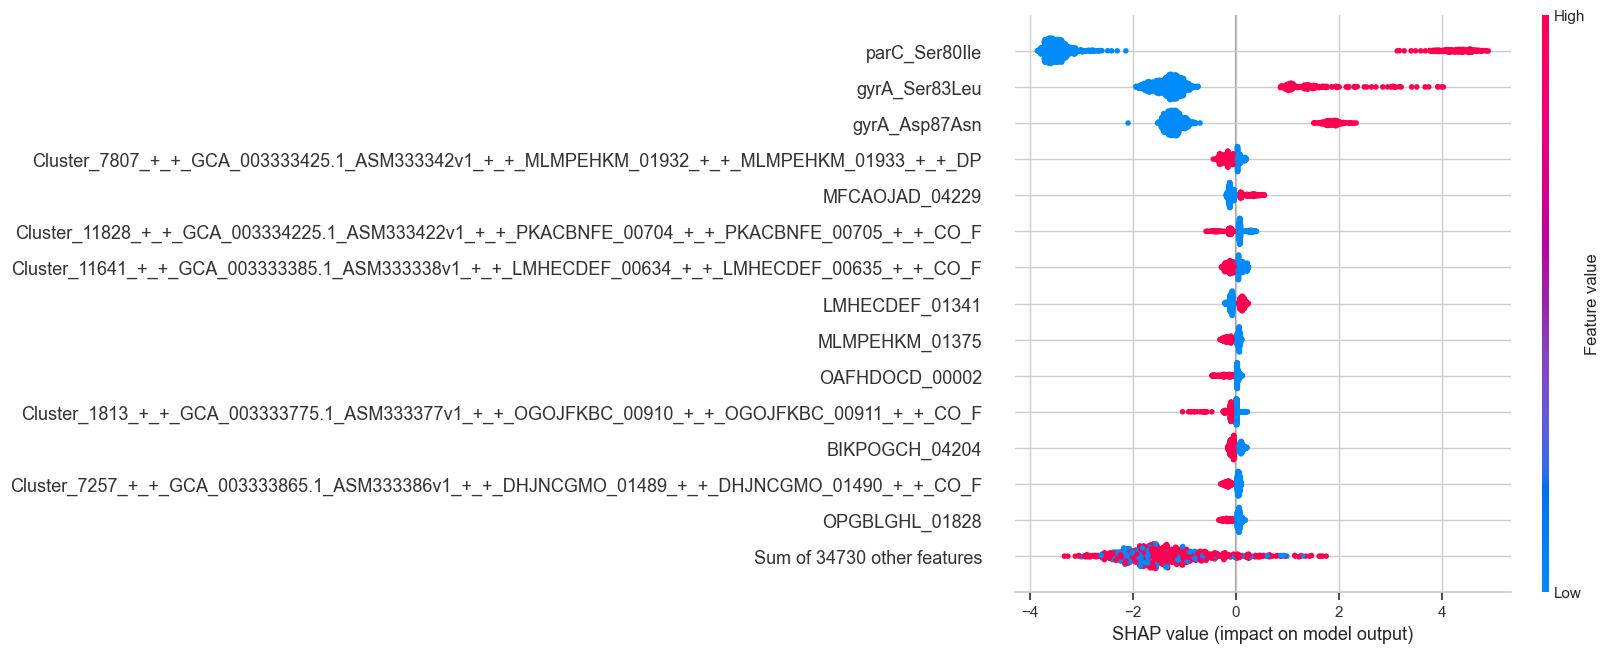

In [12]:
import shap

shap.plots.beeswarm(res_cipro.shap_values, max_display=15)

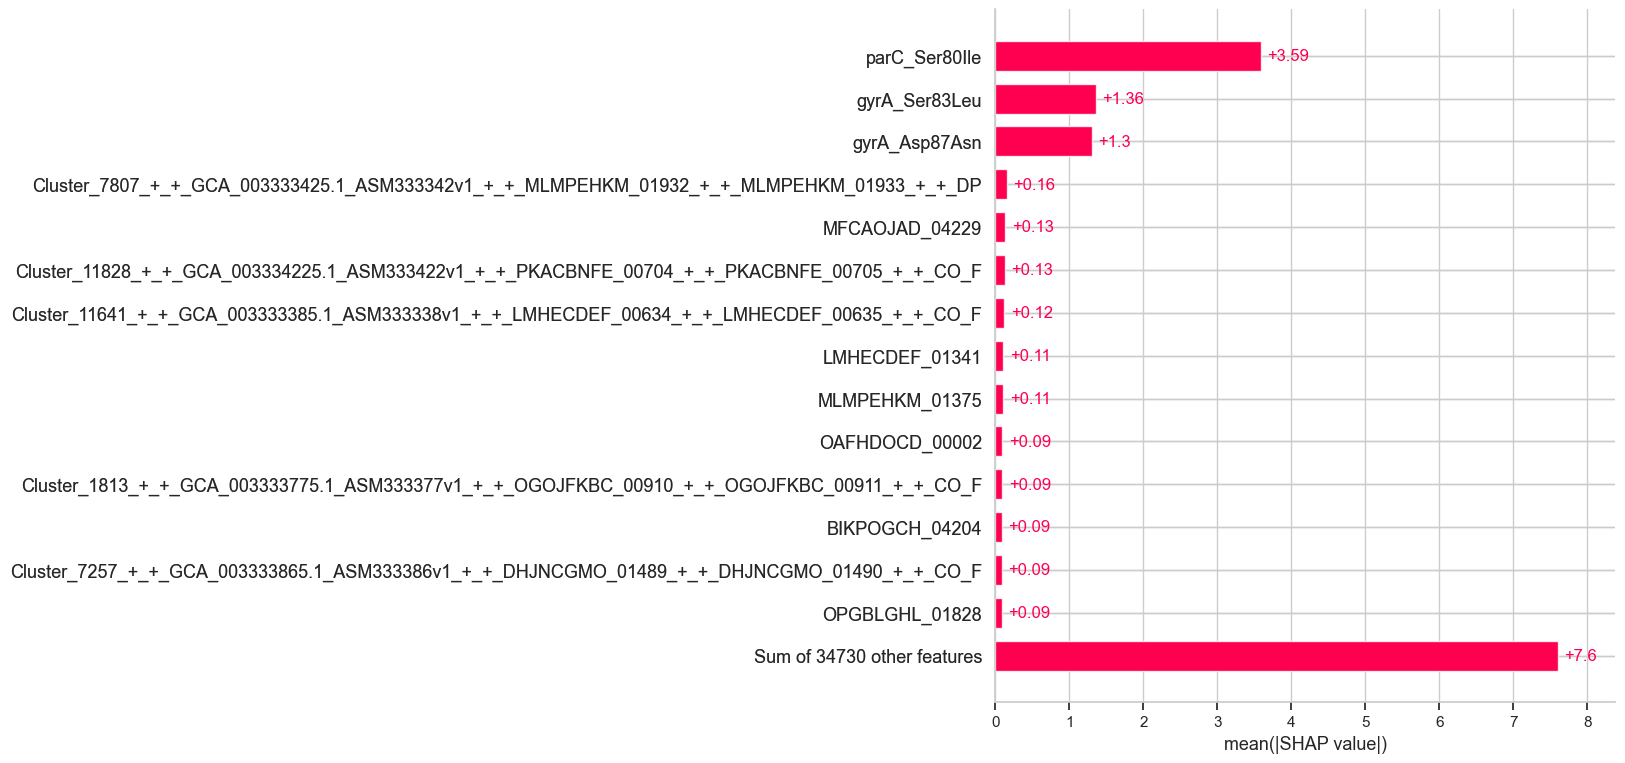

In [13]:
shap.plots.bar(res_cipro.shap_values, max_display=15)

## 8. Boucle sur les antibiotiques

`compute_shap=False` dans la boucle : on ne garde pas les objets SHAP de tous les ATB en mémoire. SHAP est recalculé plus tard uniquement pour les ATB à analyser en détail.

In [ ]:
results = {}

for atb in ATB_CIBLES:
    try:
        results[atb] = run_antibiotic_pipeline(
            atb=atb,
            data=data,
            compute_shap=False,
            save_dir=MODEL_DIR,
            verbose=True,
        )
    except Exception as exc:
        print(f"[SKIP] {atb}: {exc}")

print(f"\n{len(results)}/{len(ATB_CIBLES)} antibiotiques traités.")


=== ciprofloxacin ===
n_train=4050 | n_val=946 | n_test=939
prévalence train/val/test = 23.48% / 17.86% / 17.57%
  xgb    | val PR-AUC=0.968 | val F1=0.958 @ seuil=0.048
  lr_l1  | val PR-AUC=0.961 | val F1=0.955 @ seuil=0.680
  → meilleur modèle : xgb (seuil validation = 0.048)
  TEST   | AUC=0.982 | PR-AUC=0.977 | F1=0.946 | P=0.940 | R=0.952

=== ampicillin ===
n_train=3245 | n_val=822 | n_test=784
prévalence train/val/test = 51.09% / 48.18% / 47.83%
  xgb    | val PR-AUC=0.960 | val F1=0.917 @ seuil=0.550
  lr_l1  | val PR-AUC=0.945 | val F1=0.906 @ seuil=0.290
  → meilleur modèle : xgb (seuil validation = 0.550)
  TEST   | AUC=0.956 | PR-AUC=0.960 | F1=0.902 | P=0.917 | R=0.888

=== cefuroxime ===
n_train=2676 | n_val=769 | n_test=656
prévalence train/val/test = 14.28% / 11.57% / 10.98%
  xgb    | val PR-AUC=0.667 | val F1=0.658 @ seuil=0.277


## 9. Tableau récapitulatif

Pour un jeu déséquilibré, la **PR-AUC** est plus informative que l'AUC. Sa baseline est la prévalence de la classe positive : un modèle aléatoire obtient une PR-AUC proche de cette prévalence.

On calcule donc aussi le **gain de PR-AUC** par rapport à cette baseline.

In [ ]:
rows = []

for atb, res in results.items():
    metrics = res.metrics_test[res.best_model_name]
    rows.append(
        {
            "atb": atb,
            "n_train": res.n_train,
            "n_val": res.n_val,
            "n_test": res.n_test,
            "prevalence_test_%": round(100 * res.prevalence_test, 1),
            "best_model": res.best_model_name,
            "threshold": round(res.best_threshold, 3),
            "val_pr_auc": round(res.metrics_val[res.best_model_name]["pr_auc"], 4),
            "test_auc": round(metrics["roc_auc"], 4),
            "test_pr_auc": round(metrics["pr_auc"], 4),
            "test_f1": round(metrics["f1"], 4),
            "test_precision": round(metrics["precision"], 4),
            "test_recall": round(metrics["recall"], 4),
        }
    )

summary = (
    pd.DataFrame(rows)
    .sort_values("test_pr_auc", ascending=False)
    .reset_index(drop=True)
)
summary["baseline_pr_auc"] = summary["prevalence_test_%"] / 100
summary["gain_pr_auc"] = (
    summary["test_pr_auc"] - summary["baseline_pr_auc"]
).round(4)
summary["critere"] = np.where(
    summary["atb"].isin(coverage.index[coverage["eligible_10"]]),
    "strict",
    "étendu",
)

summary.to_csv(REPORT_DIR / "summary_by_atb.csv", index=False)
summary.round(4)

,atb,n_train,n_val,n_test,prevalence_test_%,best_model,threshold,val_pr_auc,test_auc,test_pr_auc,test_f1,test_precision,test_recall,baseline_pr_auc,gain_pr_auc,critere
0,ciprofloxacin,4050,946,939,17.6,xgb,0.048,0.9683,0.9820,0.9769,0.9458,0.9401,0.9515,0.176,0.8009,strict
1,ampicillin,3245,822,784,47.8,xgb,0.550,0.9602,0.9560,0.9602,0.9024,0.9174,0.8880,0.478,0.4822,strict
2,trimethoprim/sulfamethoxazole,2285,567,522,30.3,xgb,0.551,0.8806,0.9230,0.8534,0.7509,0.8425,0.6772,0.303,0.5504,strict
3,cefotaxime,3654,862,852,11.5,xgb,0.691,0.8447,0.9630,0.8379,0.7044,0.9180,0.5714,0.115,0.7229,étendu
4,gentamicin,4042,935,933,9.1,xgb,0.157,0.7607,0.9645,0.8095,0.7802,0.7320,0.8353,0.091,0.7185,étendu
5,ceftazidime,3881,943,921,9.6,xgb,0.223,0.7987,0.9555,0.7206,0.6173,0.6757,0.5682,0.096,0.6246,étendu
6,cefuroxime,2676,769,656,11.0,xgb,0.277,0.6671,0.8326,0.6486,0.5854,0.7059,0.5000,0.110,0.5386,strict
7,amoxicillin/clavulanic acid,2542,560,608,31.1,xgb,0.037,0.5248,0.7429,0.5129,0.5751,0.4429,0.8201,0.311,0.2019,strict


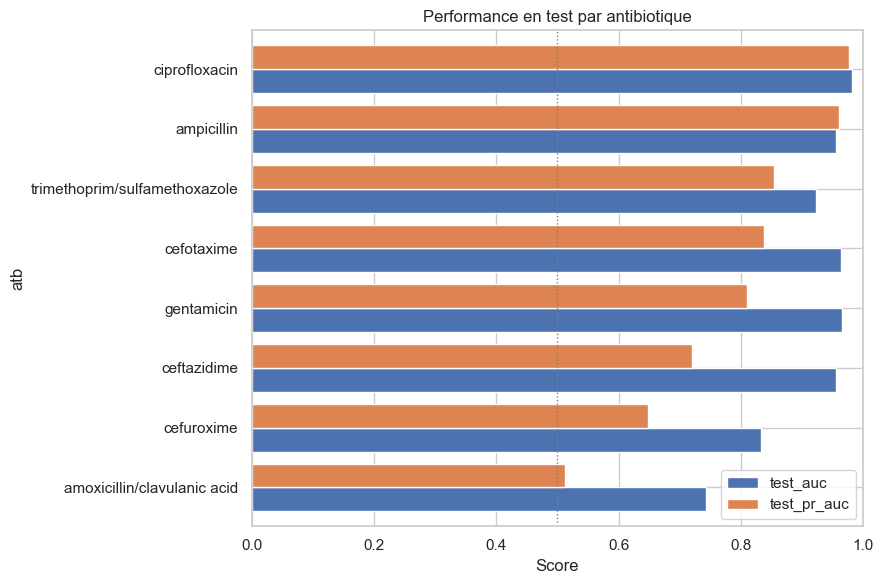

In [ ]:
plot_df = (
    summary.set_index("atb")[["test_auc", "test_pr_auc"]]
    .sort_values("test_pr_auc")
)

fig, ax = plt.subplots(figsize=(9, 0.5 * len(plot_df) + 2))
plot_df.plot.barh(
    ax=ax,
    color=["#4c72b0", "#dd8452"],
    width=0.8,
)
ax.set_xlim(0, 1)
ax.set_xlabel("Score")
ax.set_title("Performance en test par antibiotique")
ax.axvline(0.5, color="grey", linestyle=":", linewidth=1)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 10. Recharger un modèle sauvegardé

Chaque antibiotique est sauvegardé dans `models/by_atb/<atb>.joblib`, avec son seuil et ses métriques.

In [ ]:
artifact = joblib.load(MODEL_DIR / "ciprofloxacin.joblib")

print(
    f"ATB : {artifact['atb']} | "
    f"modèle : {artifact['best_model_name']} | "
    f"seuil : {artifact['threshold']:.3f}"
)
pd.DataFrame(artifact["metrics_test"]).T.round(4)

ATB : ciprofloxacin | modèle : xgb | seuil : 0.048


,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc,threshold
xgb,0.9808,0.9693,0.9401,0.9515,0.9458,0.9820,0.9769,0.048
lr_l1,0.9819,0.9533,0.9868,0.9091,0.9464,0.9811,0.9680,0.680


In [ ]:
# Exemple de prédiction sur le test
splits_cipro = prepare_data_for_atb("ciprofloxacin", data)
X_test_cipro, y_test_cipro = splits_cipro["test"]

proba_cipro = artifact["model"].predict_proba(X_test_cipro)[:, 1]
pred_cipro = (proba_cipro >= artifact["threshold"]).astype(int)

print(f"{len(y_test_cipro)} génomes testés pour ciprofloxacine")
print(f"Résistants prédits : {pred_cipro.sum()}")
print(f"Résistants réels   : {int(y_test_cipro.sum())}")

939 génomes testés pour ciprofloxacine
Résistants prédits : 167
Résistants réels   : 165
